(mean_var_portfolio:title)= 
# Mean-Variance Portfolio

In this example, we consider a portfolio optimization problem discussed in {cite:ps}`Ben_Nemirovski_2000robust`. Suppose there are $n=150$ stocks, and each stock $i$ has the mean return to be $p_i$ and the standard deviation to be $\sigma_i$. Let $x_i$ be the fraction of the total wealth invested in stock $i$, a classic approach is to formulate the problem as a quadratic program, where a mean-variance objective function is maximized:

```{math}
\begin{aligned}
\max~&\sum\limits_{i=1}^np_ix_i - \phi \sum\limits_{i=1}^n \sigma_i^2x_i^2 \\
\text{s.t.}~&\sum\limits_{i=1}^nx_i = 1 \\
& \pmb{x} \in \mathbb{R}_+^n,
\end{aligned}
```

with the constant $\phi=5$, and the means and standard deviations are specified as

```{math}
\begin{aligned}
&p_i = 1.15 + i\frac{0.05}{150} & \forall i = 1, 2, ..., n\\
&\sigma_i = \frac{0.05}{450}\sqrt{2in(n+1)} & \forall i = 1, 2, ..., n.
\end{aligned}
```

The quadratic program can be implemented by the following code segment.

In [1]:
from rsome import ro
import rsome as rso
import numpy as np

n = 150                                     # number of stocks
i = np.arange(1, n+1)                       # indices of stocks
p = 1.15 + i*0.05/150                       # mean returns
sigma = 0.05/450 * (2*i*n*(n+1))**0.5       # standard deviations of returns
phi = 5                                     # constant phi

model = ro.Model()                          # create an RSOME model

x = model.dvar(n)                           # x variable as fractions of investment

Q = np.diag(sigma**2)                       # covariance matrix
model.max(p@x - phi*rso.quad(x, Q))         # mean-variance objective
model.st(x.sum() == 1)                      # summation of x is one
model.st(x >= 0)                            # x is non-negative

model.solve()                               # solve the model

Being solved by ECOS 2.0.14...
Solution status: Optimal solution found
Running time: 0.0037s


The optimal investment and the optimal objective value are shown below.

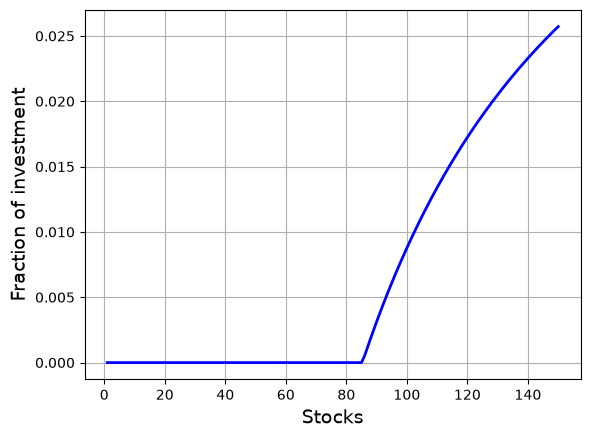

Objective value: 1.1853


In [2]:
import matplotlib.pyplot as plt

obj_val = model.get()               # the optimal objective value
x_sol = x.get()                     # the optimal investment decision

plt.plot(range(1, n+1), x_sol,
         linewidth=2, color='b')
plt.xlabel('Stocks', fontsize=14)
plt.ylabel('Fraction of investment', fontsize=14)
plt.grid()
plt.show()
print('Objective value: {0:0.4f}'.format(obj_val))

<br>

---

<font size="5">Reference</font>

```{bibliography}
:filter: docname in docnames
```